# ABLATION STUDY - EXP 1: LOG TRANSFORMATION & FEATURE SCALING

**Mục tiêu nghiên cứu:**
Đánh giá tác động độc lập và kết hợp của các kỹ thuật tiền xử lý biến số liên tục (Numerical Features) đối với bài toán phân loại hành vi mua hàng (`Revenue`), gồm 2 thử nghiệm (Ablation Setups):
1. **TN1 (Thực nghiệm 1 - Chỉ Feature Scaling):** Áp dụng `StandardScaler` lên toàn bộ các biến số liên tục (10 biến).
2. **TN2 (Thực nghiệm 2 - Log1p + Feature Scaling):** Áp dụng biến đổi Logarit (`np.log1p`) lên các biến có độ lệch dương lớn (Skewness cao), sau đó áp dụng `StandardScaler`. Các biến số còn lại chỉ chuẩn hóa `StandardScaler`.

Cả 2 thử nghiệm được thẩm định chéo (12-Fold CV) và kiểm định độc lập trên tập Hold-out Test (20%) trên **cả 3 kiến trúc mô hình**:
- **Tuyến tính:** Logistic Regression
- **Cây quyết định Boosting:** XGBoost
- **Mạng nơ-ron sâu:** Multi-Layer Perceptron (PyTorch MLP 16-8-1)

Toàn bộ kết quả được đối chiếu trực tiếp với kết quả **Baseline (Exp 0)** đã lưu trữ trong `experiment_results.json`.


In [1]:
# Tự động kết nối Google Drive nếu đang chạy trên Google Colab
import os
import sys

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = '/content/drive/MyDrive/DL_Business'
    if os.path.exists(PROJECT_DIR):
        os.chdir(PROJECT_DIR)
        if PROJECT_DIR not in sys.path:
            sys.path.insert(0, PROJECT_DIR)
        print(f"✓ Đã kết nối thành công! Thư mục hiện tại: {os.getcwd()}")
    else:
        print(f"⚠️ Không tìm thấy đường dẫn: {PROJECT_DIR}")
        print("Vui lòng kiểm tra lại tên thư mục trên Drive của bạn.")


Mounted at /content/drive
✓ Đã kết nối thành công! Thư mục hiện tại: /content/drive/MyDrive/DL_Business


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

import torch

# Import các công cụ đánh giá, ghi nhận và mô hình PyTorch MLP từ logger.py & visualization.py
from logger import (
    get_cv_scorers,
    log_experiment,
    load_experiments_df,
    load_experiments_json,
    DEVICE,
    MLPNet,
    train_pytorch_mlp,
    predict_proba_mlp,
    cross_validate_mlp
)
from visualization import (
    plot_confusion_matrix,
    plot_pr_curve,
    plot_learning_curves
)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# ==========================================
# HYPERPARAMETERS & REPRODUCIBILITY CONFIG
# ==========================================
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 4
N_REPEATS = 3


## 1. Đọc dữ liệu & Phân chia Tập dữ liệu (Train 80% / Test 20%)


In [3]:
# 1. Đọc dữ liệu
df = pd.read_csv('online_shoppers_intention.csv')

# 2. Loại bỏ duplicate
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_removed = n_before - len(df)
print(f"-> Số dòng duplicate đã loại bỏ: {n_removed:,}")

# 3. Tách X và y
X = df.drop(columns=['Revenue'])
y = df['Revenue'].astype(int)

# 4. Phân chia Train/Test 80/20 có phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
    shuffle=True
)

print(f"-> Tập Train: {X_train.shape[0]:,} phiên (Tỷ lệ mua: {y_train.mean()*100:.2f}%)")
print(f"-> Tập Test:  {X_test.shape[0]:,} phiên (Tỷ lệ mua: {y_test.mean()*100:.2f}%)")


-> Số dòng duplicate đã loại bỏ: 125
-> Tập Train: 9,764 phiên (Tỷ lệ mua: 15.63%)
-> Tập Test:  2,441 phiên (Tỷ lệ mua: 15.65%)


## 2. Thiết kế Tiền xử lý (TN1 vs TN2) & Khởi tạo Mô hình


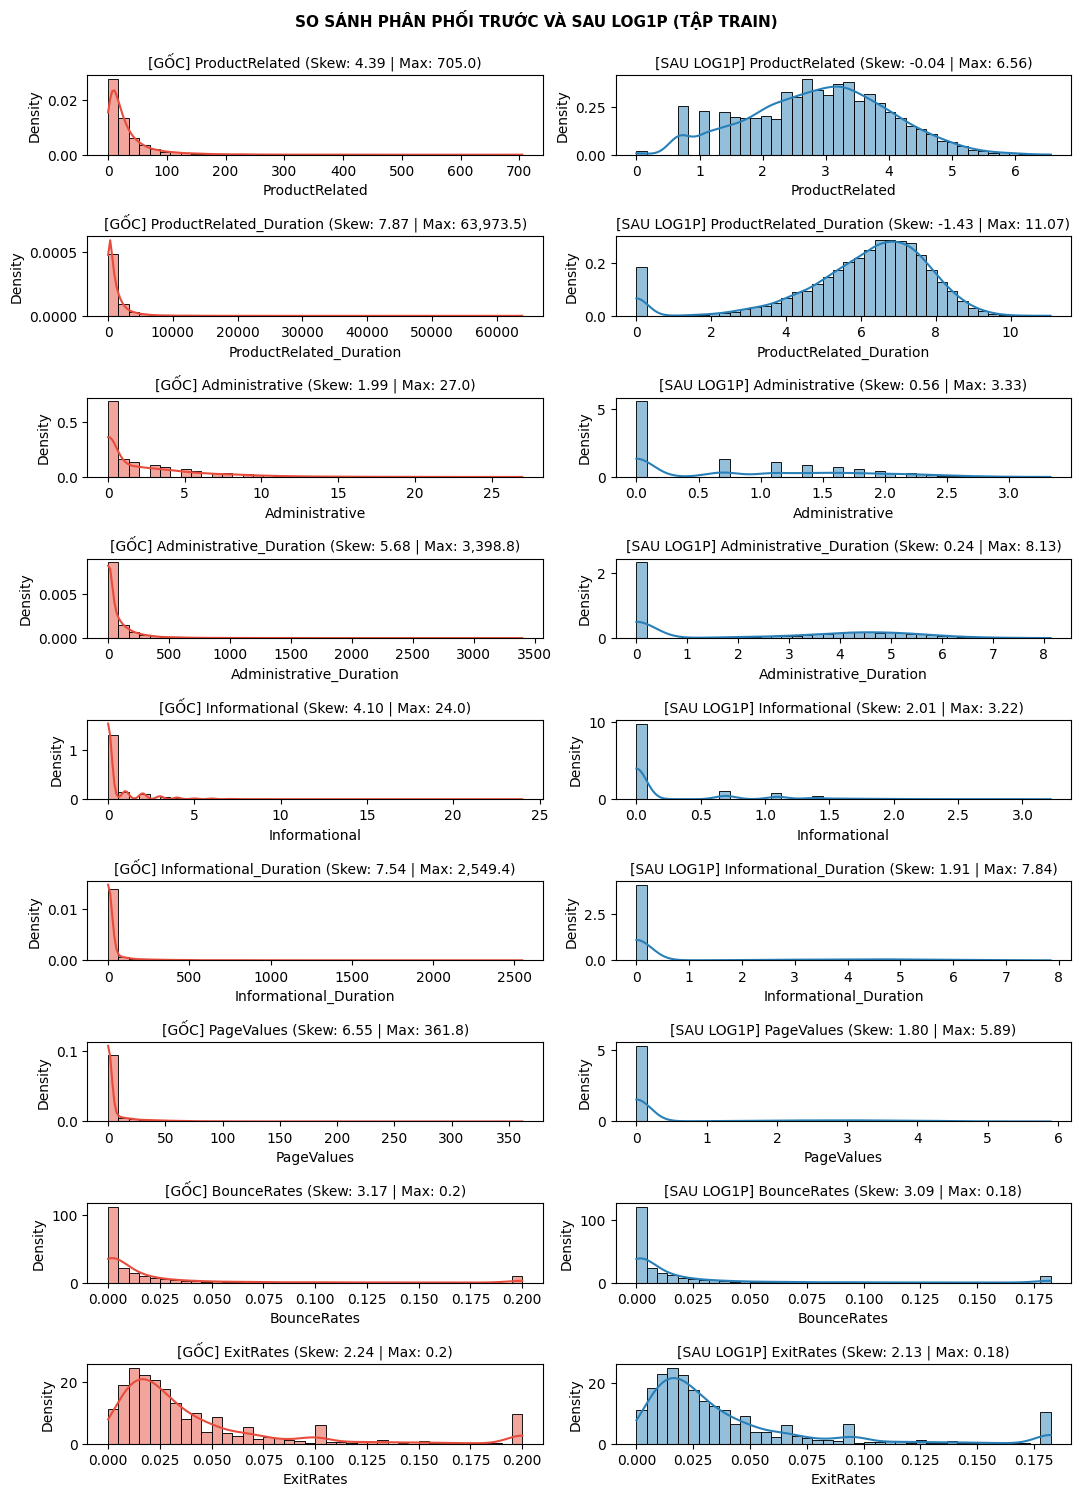

In [4]:
# Phân tích độ lệch Skewness và trực quan hóa phân phối trước/sau Log1p
candidate_cols = [
    'ProductRelated', 'ProductRelated_Duration',
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'PageValues', 'BounceRates', 'ExitRates'
]

fig, axes = plt.subplots(len(candidate_cols), 2, figsize=(11, 15))

for idx, col in enumerate(candidate_cols):
    raw_col = X_train[col]
    log_col = np.log1p(raw_col)

    # 1. Biểu đồ gốc
    sns.histplot(raw_col, bins=40, kde=True, ax=axes[idx, 0], color='#E74C3C', stat='density', alpha=0.5)
    axes[idx, 0].set_title(f"[GỐC] {col} (Skew: {raw_col.skew():.2f} | Max: {raw_col.max():,.1f})", fontsize=10)

    # 2. Biểu đồ sau Log1p
    sns.histplot(log_col, bins=40, kde=True, ax=axes[idx, 1], color='#2980B9', stat='density', alpha=0.5)
    axes[idx, 1].set_title(f"[SAU LOG1P] {col} (Skew: {log_col.skew():.2f} | Max: {log_col.max():.2f})", fontsize=10)

plt.suptitle("SO SÁNH PHÂN PHỐI TRƯỚC VÀ SAU LOG1P (TẬP TRAIN)", fontsize=11, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


In [5]:
# Định nghĩa các nhóm đặc trưng
log_cols = [
    'Administrative', 'Administrative_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'PageValues'
]
num_cols = ['Informational', 'Informational_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
all_num_cols = log_cols + num_cols
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

# ==============================================================================
# 1. BỘ TIỀN XỬ LÝ CHO TN1 (Chỉ StandardScaler) & TN2 (Log1p + StandardScaler)
# ==============================================================================
# TN1: Chỉ StandardScaler toàn bộ biến số
preprocessor_tn1 = ColumnTransformer(
    transformers=[
        ('num_scale', StandardScaler(), all_num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# TN2: Log1p biến lệch + StandardScaler
log_standard_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p, validate=True)),
    ('scaler', StandardScaler())
])

preprocessor_tn2 = ColumnTransformer(
    transformers=[
        ('log_scale', log_standard_pipe, log_cols),
        ('num_scale', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# ==============================================================================
# 2. XÂY DỰNG PIPELINES CHO LOGISTIC REGRESSION & XGBOOST
# ==============================================================================
# Logistic Regression
pipe_lr_tn1 = Pipeline([
    ('prep', preprocessor_tn1),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipe_lr_tn2 = Pipeline([
    ('prep', preprocessor_tn2),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# XGBoost
pipe_xgb_tn1 = Pipeline([
    ('prep', preprocessor_tn1),
    ('clf', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1))
])
pipe_xgb_tn2 = Pipeline([
    ('prep', preprocessor_tn2),
    ('clf', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1))
])

print("-> Đã khởi tạo thành công Pipelines cho Logistic Regression và XGBoost (TN1 & TN2)!")


-> Đã khởi tạo thành công Pipelines cho Logistic Regression và XGBoost (TN1 & TN2)!


In [6]:
# ==============================================================================
# 3. THIẾT LẬP MÔ HÌNH PYTORCH MLP (ĐÓNG GÓI TÁI SỬ DỤNG TỪ LOGGER.PY)
# ==============================================================================
# Kiến trúc MLPNet (Dropout 0.2), train_pytorch_mlp (weight_decay 1e-3, test_size 0.15),
# predict_proba_mlp và cross_validate_mlp được tái sử dụng trực tiếp từ logger.py
print(f"-> Thiết bị tính toán cho MLP: {DEVICE}")
if torch.cuda.is_available():
    print(f"   Tên GPU: {torch.cuda.get_device_name(0)}")
print("-> Đã sẵn sàng kiến trúc MLPNet và các hàm kiểm định chéo 12-Folds từ logger.py!")


-> Thiết bị tính toán cho MLP: cpu
-> Đã sẵn sàng kiến trúc MLPNet và các hàm kiểm định chéo 12-Folds từ logger.py!


## 3. Thẩm định chéo (Repeated Stratified K-Fold: 4 Folds × 3 Repeats)


In [7]:
rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

print("-> Đang thực hiện 12-Fold Cross-Validation cho toàn bộ các mô hình (TN1 vs TN2)...\n")

# 1. Logistic Regression
print("1. Đang chạy CV: Logistic Regression (TN1 & TN2)...")
cv_lr_tn1 = cross_validate(pipe_lr_tn1, X_train, y_train, cv=rskf, scoring=get_cv_scorers(), n_jobs=-1)
cv_lr_tn2 = cross_validate(pipe_lr_tn2, X_train, y_train, cv=rskf, scoring=get_cv_scorers(), n_jobs=-1)

# 2. XGBoost
print("2. Đang chạy CV: XGBoost (TN1 & TN2)...")
cv_xgb_tn1 = cross_validate(pipe_xgb_tn1, X_train, y_train, cv=rskf, scoring=get_cv_scorers(), n_jobs=-1)
cv_xgb_tn2 = cross_validate(pipe_xgb_tn2, X_train, y_train, cv=rskf, scoring=get_cv_scorers(), n_jobs=-1)

# 3. PyTorch MLP
print("3. Đang chạy CV: PyTorch MLP (TN1 & TN2)...")
cv_mlp_tn1 = cross_validate_mlp(X_train, y_train, preprocessor_tn1, rskf, random_state=RANDOM_STATE)
cv_mlp_tn2 = cross_validate_mlp(X_train, y_train, preprocessor_tn2, rskf, random_state=RANDOM_STATE)

# Tổng hợp bảng so sánh CV (12 Folds) cho cả 3 mô hình
cv_compare_table = pd.DataFrame({
    'Mô hình': [
        'Logistic Regression', 'Logistic Regression',
        'XGBoost', 'XGBoost',
        'MLP (PyTorch)', 'MLP (PyTorch)'
    ],
    'Tiền xử lý': [
        'TN1: Chỉ StandardScaler', 'TN2: Log1p + StandardScaler',
        'TN1: Chỉ StandardScaler', 'TN2: Log1p + StandardScaler',
        'TN1: Chỉ StandardScaler', 'TN2: Log1p + StandardScaler'
    ],
    'CV AP (%)': [
        f"{cv_lr_tn1['test_ap'].mean()*100:.2f} ± {cv_lr_tn1['test_ap'].std()*100:.2f}",
        f"{cv_lr_tn2['test_ap'].mean()*100:.2f} ± {cv_lr_tn2['test_ap'].std()*100:.2f}",
        f"{cv_xgb_tn1['test_ap'].mean()*100:.2f} ± {cv_xgb_tn1['test_ap'].std()*100:.2f}",
        f"{cv_xgb_tn2['test_ap'].mean()*100:.2f} ± {cv_xgb_tn2['test_ap'].std()*100:.2f}",
        f"{cv_mlp_tn1['test_ap'].mean()*100:.2f} ± {cv_mlp_tn1['test_ap'].std()*100:.2f}",
        f"{cv_mlp_tn2['test_ap'].mean()*100:.2f} ± {cv_mlp_tn2['test_ap'].std()*100:.2f}"
    ],
    'CV Precision (Mua) (%)': [
        f"{cv_lr_tn1['test_prec_1'].mean()*100:.2f} ± {cv_lr_tn1['test_prec_1'].std()*100:.2f}",
        f"{cv_lr_tn2['test_prec_1'].mean()*100:.2f} ± {cv_lr_tn2['test_prec_1'].std()*100:.2f}",
        f"{cv_xgb_tn1['test_prec_1'].mean()*100:.2f} ± {cv_xgb_tn1['test_prec_1'].std()*100:.2f}",
        f"{cv_xgb_tn2['test_prec_1'].mean()*100:.2f} ± {cv_xgb_tn2['test_prec_1'].std()*100:.2f}",
        f"{cv_mlp_tn1['test_prec_1'].mean()*100:.2f} ± {cv_mlp_tn1['test_prec_1'].std()*100:.2f}",
        f"{cv_mlp_tn2['test_prec_1'].mean()*100:.2f} ± {cv_mlp_tn2['test_prec_1'].std()*100:.2f}"
    ],
    'CV Recall (Mua) (%)': [
        f"{cv_lr_tn1['test_rec_1'].mean()*100:.2f} ± {cv_lr_tn1['test_rec_1'].std()*100:.2f}",
        f"{cv_lr_tn2['test_rec_1'].mean()*100:.2f} ± {cv_lr_tn2['test_rec_1'].std()*100:.2f}",
        f"{cv_xgb_tn1['test_rec_1'].mean()*100:.2f} ± {cv_xgb_tn1['test_rec_1'].std()*100:.2f}",
        f"{cv_xgb_tn2['test_rec_1'].mean()*100:.2f} ± {cv_xgb_tn2['test_rec_1'].std()*100:.2f}",
        f"{cv_mlp_tn1['test_rec_1'].mean()*100:.2f} ± {cv_mlp_tn1['test_rec_1'].std()*100:.2f}",
        f"{cv_mlp_tn2['test_rec_1'].mean()*100:.2f} ± {cv_mlp_tn2['test_rec_1'].std()*100:.2f}"
    ],
    'CV F1 (Mua) (%)': [
        f"{cv_lr_tn1['test_f1_1'].mean()*100:.2f} ± {cv_lr_tn1['test_f1_1'].std()*100:.2f}",
        f"{cv_lr_tn2['test_f1_1'].mean()*100:.2f} ± {cv_lr_tn2['test_f1_1'].std()*100:.2f}",
        f"{cv_xgb_tn1['test_f1_1'].mean()*100:.2f} ± {cv_xgb_tn1['test_f1_1'].std()*100:.2f}",
        f"{cv_xgb_tn2['test_f1_1'].mean()*100:.2f} ± {cv_xgb_tn2['test_f1_1'].std()*100:.2f}",
        f"{cv_mlp_tn1['test_f1_1'].mean()*100:.2f} ± {cv_mlp_tn1['test_f1_1'].std()*100:.2f}",
        f"{cv_mlp_tn2['test_f1_1'].mean()*100:.2f} ± {cv_mlp_tn2['test_f1_1'].std()*100:.2f}"
    ],
    'CV F1-Macro (%)': [
        f"{cv_lr_tn1['test_f1_macro'].mean()*100:.2f} ± {cv_lr_tn1['test_f1_macro'].std()*100:.2f}",
        f"{cv_lr_tn2['test_f1_macro'].mean()*100:.2f} ± {cv_lr_tn2['test_f1_macro'].std()*100:.2f}",
        f"{cv_xgb_tn1['test_f1_macro'].mean()*100:.2f} ± {cv_xgb_tn1['test_f1_macro'].std()*100:.2f}",
        f"{cv_xgb_tn2['test_f1_macro'].mean()*100:.2f} ± {cv_xgb_tn2['test_f1_macro'].std()*100:.2f}",
        f"{cv_mlp_tn1['test_f1_macro'].mean()*100:.2f} ± {cv_mlp_tn1['test_f1_macro'].std()*100:.2f}",
        f"{cv_mlp_tn2['test_f1_macro'].mean()*100:.2f} ± {cv_mlp_tn2['test_f1_macro'].std()*100:.2f}"
    ]
})

print("="*85)
print("BẢNG TỔNG HỢP CROSS-VALIDATION (12 FOLDS) - TẤT CẢ CÁC MÔ HÌNH (EXP 1: TN1 vs TN2):")
print("="*85)
display(cv_compare_table.set_index(['Mô hình', 'Tiền xử lý']))


-> Đang thực hiện 12-Fold Cross-Validation cho toàn bộ các mô hình (TN1 vs TN2)...

1. Đang chạy CV: Logistic Regression (TN1 & TN2)...
2. Đang chạy CV: XGBoost (TN1 & TN2)...
3. Đang chạy CV: PyTorch MLP (TN1 & TN2)...
BẢNG TỔNG HỢP CROSS-VALIDATION (12 FOLDS) - TẤT CẢ CÁC MÔ HÌNH (EXP 1: TN1 vs TN2):


CV AP (%)  \
Mô hình             Tiền xử lý                                  
Logistic Regression TN1: Chỉ StandardScaler      63.74 ± 2.58   
                    TN2: Log1p + StandardScaler  68.15 ± 2.07   
XGBoost             TN1: Chỉ StandardScaler      71.70 ± 1.97   
                    TN2: Log1p + StandardScaler  71.70 ± 1.97   
MLP (PyTorch)       TN1: Chỉ StandardScaler      71.62 ± 1.98   
                    TN2: Log1p + StandardScaler  73.77 ± 1.67   

                                                CV Precision (Mua) (%)  \
Mô hình             Tiền xử lý                                           
Logistic Regression TN1: Chỉ StandardScaler               74.28 ± 3.73   
                    TN2: Log1p + StandardScaler           70.40 ± 2.64   
XGBoost             TN1: Chỉ StandardScaler               69.67 ± 3.07   
                    TN2: Log1p + StandardScaler           69.67 ± 3.07   
MLP (PyTorch)       TN1: Chỉ StandardScaler               71.57 ± 3.05   
                    TN2: Log1p + StandardScaler           71.69 ± 2.88   

                                                CV Recall (Mua) (%)  \
Mô hình             Tiền xử lý                                        
Logistic Regression TN1: Chỉ StandardScaler            37.77 ± 2.53   
                    TN2: Log1p + StandardScaler        55.11 ± 2.12   
XGBoost             TN1: Chỉ StandardScaler            58.19 ± 1.60   
                    TN2: Log1p + StandardScaler        58.19 ± 1.60   
MLP (PyTorch)       TN1: Chỉ StandardScaler            56.93 ± 4.61   
                    TN2: Log1p + StandardScaler        59.66 ± 3.89   

                                                CV F1 (Mua) (%)  \
Mô hình             Tiền xử lý                                    
Logistic Regression TN1: Chỉ StandardScaler        50.00 ± 2.37   
                    TN2: Log1p + StandardScaler    61.79 ± 1.82   
XGBoost             TN1: Chỉ StandardScaler        63.37 ± 1.50   
                    TN2: Log1p + StandardScaler    63.37 ± 1.50   
MLP (PyTorch)       TN1: Chỉ StandardScaler        63.24 ± 2.89   
                    TN2: Log1p + StandardScaler    65.01 ± 2.41   

                                                CV F1-Macro (%)  
Mô hình             Tiền xử lý                                   
Logistic Regression TN1: Chỉ StandardScaler        71.66 ± 1.30  
                    TN2: Log1p + StandardScaler    77.80 ± 1.05  
XGBoost             TN1: Chỉ StandardScaler        78.61 ± 0.92  
                    TN2: Log1p + StandardScaler    78.61 ± 0.92  
MLP (PyTorch)       TN1: Chỉ StandardScaler        78.63 ± 1.57  
                    TN2: Log1p + StandardScaler    79.58 ± 1.35

## 4. Huấn luyện toàn bộ Train & Đánh giá trên Hold-out Test (20%)


In [8]:
print("-> Đang huấn luyện toàn bộ tập Train và kiểm định trên Hold-out Test (20%)...\n")

# 1. Logistic Regression
pipe_lr_tn1.fit(X_train, y_train)
pipe_lr_tn2.fit(X_train, y_train)
pred_lr_tn1, prob_lr_tn1 = pipe_lr_tn1.predict(X_test), pipe_lr_tn1.predict_proba(X_test)[:, 1]
pred_lr_tn2, prob_lr_tn2 = pipe_lr_tn2.predict(X_test), pipe_lr_tn2.predict_proba(X_test)[:, 1]

# 2. XGBoost
pipe_xgb_tn1.fit(X_train, y_train)
pipe_xgb_tn2.fit(X_train, y_train)
pred_xgb_tn1, prob_xgb_tn1 = pipe_xgb_tn1.predict(X_test), pipe_xgb_tn1.predict_proba(X_test)[:, 1]
pred_xgb_tn2, prob_xgb_tn2 = pipe_xgb_tn2.predict(X_test), pipe_xgb_tn2.predict_proba(X_test)[:, 1]

# 3. PyTorch MLP (test_size=0.2 cho tập validation nội bộ, ghi nhận learning curves)
prep_mlp_tn1, model_mlp_tn1, hist_mlp_tn1 = train_pytorch_mlp(
    X_train, y_train, preprocessor_tn1, random_state=RANDOM_STATE, return_history=True, test_size=0.2
)
prep_mlp_tn2, model_mlp_tn2, hist_mlp_tn2 = train_pytorch_mlp(
    X_train, y_train, preprocessor_tn2, random_state=RANDOM_STATE, return_history=True, test_size=0.2
)
prob_mlp_tn1 = predict_proba_mlp(prep_mlp_tn1, model_mlp_tn1, X_test)
prob_mlp_tn2 = predict_proba_mlp(prep_mlp_tn2, model_mlp_tn2, X_test)
pred_mlp_tn1 = (prob_mlp_tn1 >= 0.5).astype(int)
pred_mlp_tn2 = (prob_mlp_tn2 >= 0.5).astype(int)

# In tóm tắt AP trên tập Test
print("="*75)
print("KẾT QUẢ ĐỘ ĐO CHÍNH AVERAGE PRECISION (AP) TRÊN TẬP TEST (20% HOLD-OUT):")
print("="*75)
print(f"1. Logistic Regression : TN1 AP = {average_precision_score(y_test, prob_lr_tn1)*100:6.2f}% | TN2 AP = {average_precision_score(y_test, prob_lr_tn2)*100:6.2f}%")
print(f"2. XGBoost             : TN1 AP = {average_precision_score(y_test, prob_xgb_tn1)*100:6.2f}% | TN2 AP = {average_precision_score(y_test, prob_xgb_tn2)*100:6.2f}%")
print(f"3. MLP (PyTorch)       : TN1 AP = {average_precision_score(y_test, prob_mlp_tn1)*100:6.2f}% | TN2 AP = {average_precision_score(y_test, prob_mlp_tn2)*100:6.2f}%")


-> Đang huấn luyện toàn bộ tập Train và kiểm định trên Hold-out Test (20%)...

KẾT QUẢ ĐỘ ĐO CHÍNH AVERAGE PRECISION (AP) TRÊN TẬP TEST (20% HOLD-OUT):
1. Logistic Regression : TN1 AP =  65.43% | TN2 AP =  69.52%
2. XGBoost             : TN1 AP =  72.42% | TN2 AP =  72.42%
3. MLP (PyTorch)       : TN1 AP =  72.82% | TN2 AP =  75.49%


## 5. So sánh Đối đầu & Trực quan hóa (So với Baseline Exp 0)


=== 1. KẾT QUẢ KIỂM ĐỊNH TEST: LOGISTIC REGRESSION ===


,Chỉ số đánh giá,Exp 0: Baseline,TN1: Chỉ StandardScaler,TN2: Log1p + StandardScaler
0,AP (Độ đo chính),65.93%,65.43%,69.52%
1,Precision (Lớp 1 - Mua),75.98%,75.71%,71.84%
2,Recall (Lớp 1 - Mua),40.58%,41.62%,59.42%
3,F1-Score (Lớp 1 - Mua),52.90%,53.72%,65.04%
4,F1-Macro,73.24%,73.66%,79.61%



=== 2. KẾT QUẢ KIỂM ĐỊNH TEST: XGBOOST ===


,Chỉ số đánh giá,Exp 0: Baseline,TN1: Chỉ StandardScaler,TN2: Log1p + StandardScaler
0,AP (Độ đo chính),71.94%,72.42%,72.42%
1,Precision (Lớp 1 - Mua),68.96%,68.06%,68.06%
2,Recall (Lớp 1 - Mua),60.47%,59.69%,59.69%
3,F1-Score (Lớp 1 - Mua),64.44%,63.60%,63.60%
4,F1-Macro,79.16%,78.67%,78.67%



=== 3. KẾT QUẢ KIỂM ĐỊNH TEST: MLP (PYTORCH) ===


,Chỉ số đánh giá,Exp 0: Baseline,TN1: Chỉ StandardScaler,TN2: Log1p + StandardScaler
0,AP (Độ đo chính),66.30%,72.82%,75.49%
1,Precision (Lớp 1 - Mua),76.04%,69.60%,74.22%
2,Recall (Lớp 1 - Mua),38.22%,64.14%,62.57%
3,F1-Score (Lớp 1 - Mua),50.87%,66.76%,67.90%
4,F1-Macro,72.16%,80.44%,81.24%


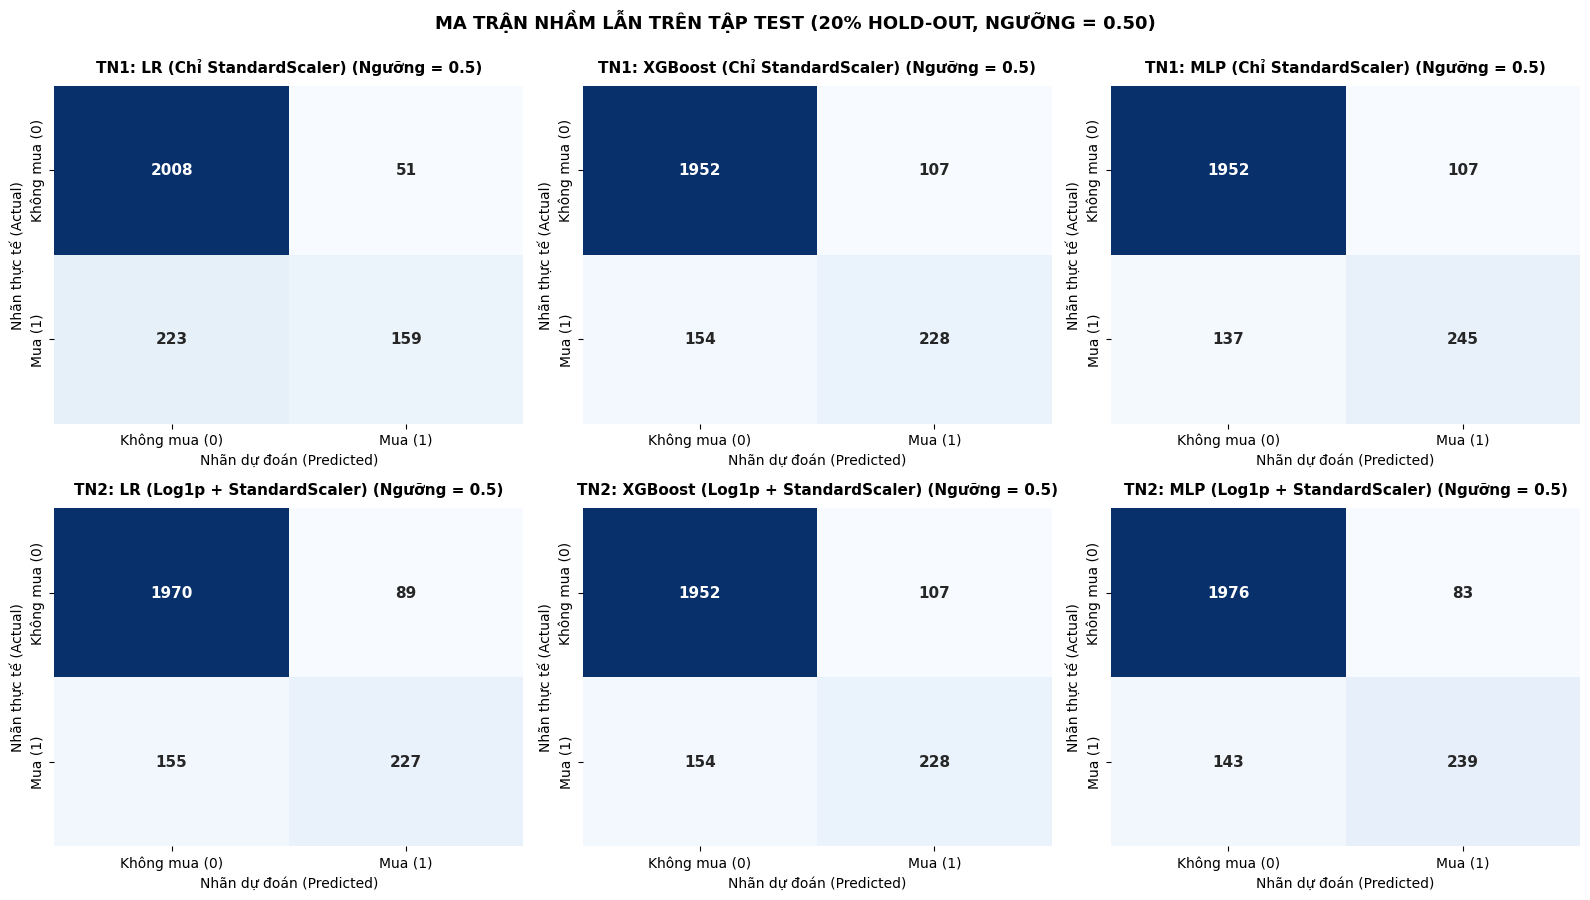

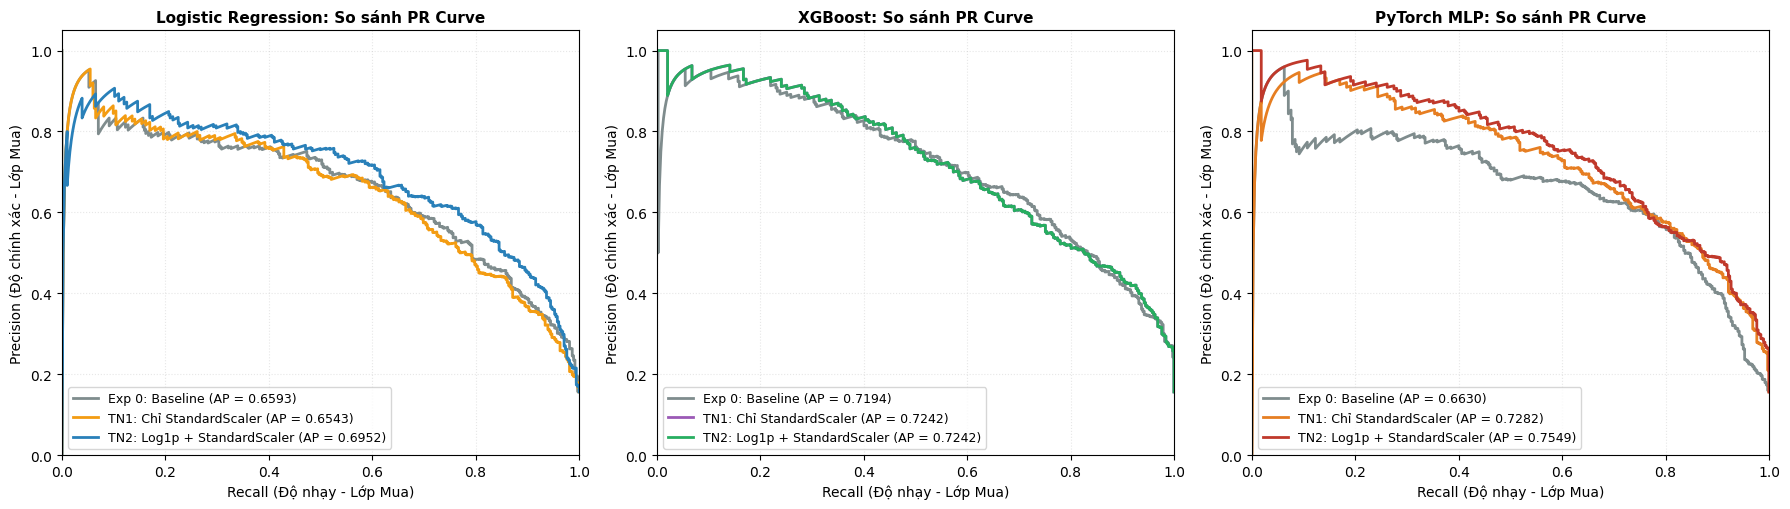


TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - PYTORCH MLP TRÊN TẬP TRAIN & VAL NỘI BỘ:


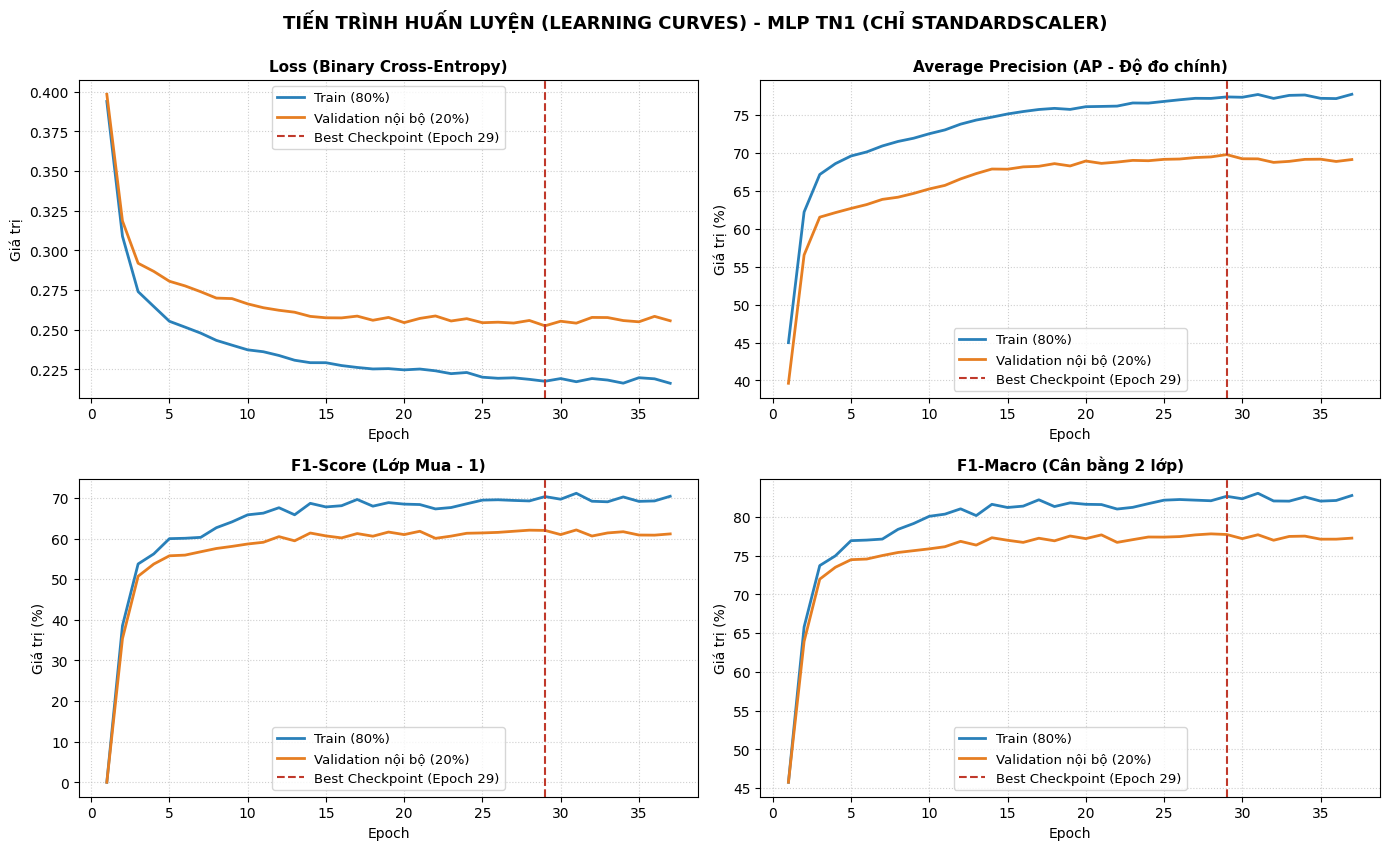

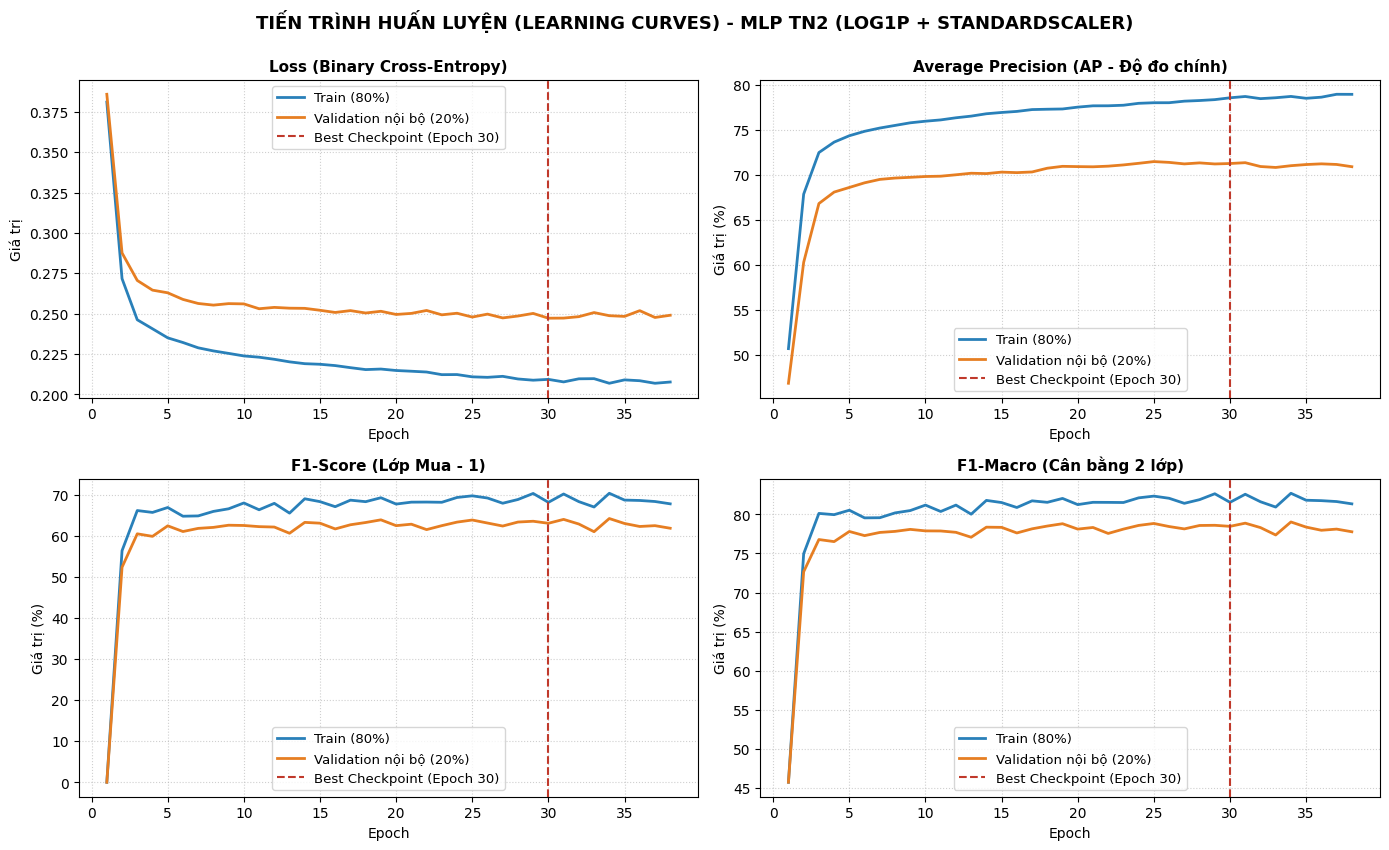

In [9]:
# ==============================================================================
# 1. HUẤN LUYỆN NHANH CÁC BASELINE (EXP 0) ĐỂ ĐỐI CHIẾU TRỰC QUAN ĐƯỜNG CONG PR
# ==============================================================================
# Baseline Logistic Regression (Passthrough numerical, OHE categorical)
preprocessor_base = ColumnTransformer([
    ('num', 'passthrough', all_num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
])
pipe_base_lr = Pipeline([
    ('prep', preprocessor_base),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
pipe_base_lr.fit(X_train, y_train)
prob_lr_base = pipe_base_lr.predict_proba(X_test)[:, 1]

# Baseline XGBoost (Chuẩn hóa CategoricalDtype đồng bộ)
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
for col in cat_cols:
    cat_type = pd.CategoricalDtype(categories=df[col].astype(str).unique().tolist())
    X_train_xgb[col] = X_train_xgb[col].astype(str).astype(cat_type)
    X_test_xgb[col] = X_test_xgb[col].astype(str).astype(cat_type)

xgb_base = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    enable_categorical=True,
    tree_method='hist',
    n_jobs=-1
)
xgb_base.fit(X_train_xgb, y_train)
prob_xgb_base = xgb_base.predict_proba(X_test_xgb)[:, 1]

# Baseline PyTorch MLP
prep_mlp_base, model_mlp_base, hist_mlp_base = train_pytorch_mlp(
    X_train, y_train, preprocessor_base, random_state=RANDOM_STATE, return_history=True, test_size=0.2
)
prob_mlp_base = predict_proba_mlp(prep_mlp_base, model_mlp_base, X_test)

# ==============================================================================
# 2. BẢNG SCORECARDS KIỂM THỊ ĐỐI CHIẾU CHO TỪNG KIẾN TRÚC MÔ HÌNH
# ==============================================================================
def build_scorecard(prob_b, prob_1, pred_1, prob_2, pred_2):
    ap_b = average_precision_score(y_test, prob_b) * 100
    p1_b = precision_score(y_test, (prob_b >= 0.5).astype(int), pos_label=1, zero_division=0) * 100
    r1_b = recall_score(y_test, (prob_b >= 0.5).astype(int), pos_label=1, zero_division=0) * 100
    f1_b = f1_score(y_test, (prob_b >= 0.5).astype(int), pos_label=1, zero_division=0) * 100
    fm_b = f1_score(y_test, (prob_b >= 0.5).astype(int), average='macro', zero_division=0) * 100

    ap_1 = average_precision_score(y_test, prob_1) * 100
    p1_1 = precision_score(y_test, pred_1, pos_label=1, zero_division=0) * 100
    r1_1 = recall_score(y_test, pred_1, pos_label=1, zero_division=0) * 100
    f1_1 = f1_score(y_test, pred_1, pos_label=1, zero_division=0) * 100
    fm_1 = f1_score(y_test, pred_1, average='macro', zero_division=0) * 100

    ap_2 = average_precision_score(y_test, prob_2) * 100
    p1_2 = precision_score(y_test, pred_2, pos_label=1, zero_division=0) * 100
    r1_2 = recall_score(y_test, pred_2, pos_label=1, zero_division=0) * 100
    f1_2 = f1_score(y_test, pred_2, pos_label=1, zero_division=0) * 100
    fm_2 = f1_score(y_test, pred_2, average='macro', zero_division=0) * 100

    return pd.DataFrame({
        'Chỉ số đánh giá': ['AP (Độ đo chính)', 'Precision (Lớp 1 - Mua)', 'Recall (Lớp 1 - Mua)', 'F1-Score (Lớp 1 - Mua)', 'F1-Macro'],
        'Exp 0: Baseline': [f"{ap_b:.2f}%", f"{p1_b:.2f}%", f"{r1_b:.2f}%", f"{f1_b:.2f}%", f"{fm_b:.2f}%"],
        'TN1: Chỉ StandardScaler': [f"{ap_1:.2f}%", f"{p1_1:.2f}%", f"{r1_1:.2f}%", f"{f1_1:.2f}%", f"{fm_1:.2f}%"],
        'TN2: Log1p + StandardScaler': [f"{ap_2:.2f}%", f"{p1_2:.2f}%", f"{r1_2:.2f}%", f"{f1_2:.2f}%", f"{fm_2:.2f}%"]
    })

print("=== 1. KẾT QUẢ KIỂM ĐỊNH TEST: LOGISTIC REGRESSION ===")
display(build_scorecard(prob_lr_base, prob_lr_tn1, pred_lr_tn1, prob_lr_tn2, pred_lr_tn2))

print("\n=== 2. KẾT QUẢ KIỂM ĐỊNH TEST: XGBOOST ===")
display(build_scorecard(prob_xgb_base, prob_xgb_tn1, pred_xgb_tn1, prob_xgb_tn2, pred_xgb_tn2))

print("\n=== 3. KẾT QUẢ KIỂM ĐỊNH TEST: MLP (PYTORCH) ===")
display(build_scorecard(prob_mlp_base, prob_mlp_tn1, pred_mlp_tn1, prob_mlp_tn2, pred_mlp_tn2))

# ==============================================================================
# 3. TRỰC QUAN HÓA MA TRẬN NHẦM LẪN (2 HÀNG x 3 CỘT: TN1 vs TN2 TRÊN 3 MÔ HÌNH)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

cms = [
    # Hàng 1: TN1 (Chỉ StandardScaler)
    (confusion_matrix(y_test, pred_lr_tn1), 'TN1: LR (Chỉ StandardScaler)', axes[0, 0]),
    (confusion_matrix(y_test, pred_xgb_tn1), 'TN1: XGBoost (Chỉ StandardScaler)', axes[0, 1]),
    (confusion_matrix(y_test, pred_mlp_tn1), 'TN1: MLP (Chỉ StandardScaler)', axes[0, 2]),
    # Hàng 2: TN2 (Log1p + StandardScaler)
    (confusion_matrix(y_test, pred_lr_tn2), 'TN2: LR (Log1p + StandardScaler)', axes[1, 0]),
    (confusion_matrix(y_test, pred_xgb_tn2), 'TN2: XGBoost (Log1p + StandardScaler)', axes[1, 1]),
    (confusion_matrix(y_test, pred_mlp_tn2), 'TN2: MLP (Log1p + StandardScaler)', axes[1, 2]),
]

for cm, title, ax in cms:
    plot_confusion_matrix(cm, ax=ax, title=title, threshold=0.5)

plt.suptitle('MA TRẬN NHẦM LẪN TRÊN TẬP TEST (20% HOLD-OUT, NGƯỠNG = 0.50)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. TRỰC QUAN HÓA ĐƯỜNG CONG PRECISION-RECALL (1 HÀNG x 3 CỘT)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Subplot 1: Logistic Regression
plot_pr_curve(y_test, prob_lr_base, model_name='Exp 0: Baseline', ax=axes[0], color='#7F8C8D')
plot_pr_curve(y_test, prob_lr_tn1, model_name='TN1: Chỉ StandardScaler', ax=axes[0], color='#F39C12')
plot_pr_curve(y_test, prob_lr_tn2, model_name='TN2: Log1p + StandardScaler', ax=axes[0], color='#2980B9')
axes[0].set_title('Logistic Regression: So sánh PR Curve', fontsize=11, fontweight='bold')

# Subplot 2: XGBoost
plot_pr_curve(y_test, prob_xgb_base, model_name='Exp 0: Baseline', ax=axes[1], color='#7F8C8D')
plot_pr_curve(y_test, prob_xgb_tn1, model_name='TN1: Chỉ StandardScaler', ax=axes[1], color='#9B59B6')
plot_pr_curve(y_test, prob_xgb_tn2, model_name='TN2: Log1p + StandardScaler', ax=axes[1], color='#27AE60')
axes[1].set_title('XGBoost: So sánh PR Curve', fontsize=11, fontweight='bold')

# Subplot 3: PyTorch MLP
plot_pr_curve(y_test, prob_mlp_base, model_name='Exp 0: Baseline', ax=axes[2], color='#7F8C8D')
plot_pr_curve(y_test, prob_mlp_tn1, model_name='TN1: Chỉ StandardScaler', ax=axes[2], color='#E67E22')
plot_pr_curve(y_test, prob_mlp_tn2, model_name='TN2: Log1p + StandardScaler', ax=axes[2], color='#C0392B')
axes[2].set_title('PyTorch MLP: So sánh PR Curve', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. TRỰC QUAN HÓA TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) CHO CÁC MÔ HÌNH MLP
# ==============================================================================
print("\n" + "="*80)
print("TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - PYTORCH MLP TRÊN TẬP TRAIN & VAL NỘI BỘ:")
print("="*80)
plot_learning_curves(hist_mlp_tn1, model_title="MLP TN1 (Chỉ StandardScaler)")
plot_learning_curves(hist_mlp_tn2, model_title="MLP TN2 (Log1p + StandardScaler)")


## 6. Lưu trữ Kết quả Thực nghiệm vào JSON & Bảng Tổng Hợp Lịch Sử


In [10]:
config = {
    'random_state': RANDOM_STATE,
    'test_size': TEST_SIZE,
    'n_splits': N_SPLITS,
    'n_repeats': N_REPEATS
}

# 1. Logistic Regression
log_experiment(
    exp_id='exp1_tn1_standard_scaler_lr',
    model_name='Logistic Regression',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN1: Chỉ StandardScaler toàn bộ biến số (Logistic Regression)',
    config=config,
    y_test=y_test,
    y_proba=prob_lr_tn1,
    y_pred=pred_lr_tn1,
    threshold=0.5,
    cv_results=cv_lr_tn1
)

log_experiment(
    exp_id='exp1_tn2_log1p_scaler_lr',
    model_name='Logistic Regression',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN2: Log1p biến lệch + StandardScaler (Logistic Regression)',
    config=config,
    y_test=y_test,
    y_proba=prob_lr_tn2,
    y_pred=pred_lr_tn2,
    threshold=0.5,
    cv_results=cv_lr_tn2
)

# 2. XGBoost
log_experiment(
    exp_id='exp1_tn1_standard_scaler_xgb',
    model_name='XGBoost',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN1: Chỉ StandardScaler toàn bộ biến số (XGBoost)',
    config=config,
    y_test=y_test,
    y_proba=prob_xgb_tn1,
    y_pred=pred_xgb_tn1,
    threshold=0.5,
    cv_results=cv_xgb_tn1
)

log_experiment(
    exp_id='exp1_tn2_log1p_scaler_xgb',
    model_name='XGBoost',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN2: Log1p biến lệch + StandardScaler (XGBoost)',
    config=config,
    y_test=y_test,
    y_proba=prob_xgb_tn2,
    y_pred=pred_xgb_tn2,
    threshold=0.5,
    cv_results=cv_xgb_tn2
)

# 3. PyTorch MLP
log_experiment(
    exp_id='exp1_tn1_standard_scaler_mlp',
    model_name='MLP (PyTorch)',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN1: Chỉ StandardScaler toàn bộ biến số (MLP 16-8-1)',
    config=config,
    y_test=y_test,
    y_proba=prob_mlp_tn1,
    y_pred=pred_mlp_tn1,
    threshold=0.5,
    cv_results=cv_mlp_tn1
)

log_experiment(
    exp_id='exp1_tn2_log1p_scaler_mlp',
    model_name='MLP (PyTorch)',
    notebook='exp1_transform_scale.ipynb',
    description='Exp 1 TN2: Log1p biến lệch + StandardScaler (MLP 16-8-1)',
    config=config,
    y_test=y_test,
    y_proba=prob_mlp_tn2,
    y_pred=pred_mlp_tn2,
    threshold=0.5,
    cv_results=cv_mlp_tn2
)

print("-> Đã lưu thành công kết quả cả 6 biến thể thực nghiệm Exp 1 vào experiment_results.json!\n")

print("="*85)
print("BẢNG TỔNG HỢP CROSS-VALIDATION TẤT CẢ CÁC MÔ HÌNH (12 FOLDS, %):")
print("="*85)
display(load_experiments_df(view='cv'))

print("\n" + "="*85)
print("BẢNG TỔNG HỢP KIỂM ĐỊNH HOLD-OUT TEST TẤT CẢ CÁC MÔ HÌNH (NGƯỠNG = 0.50, %):")
print("="*85)
display(load_experiments_df(view='test'))


-> Đã lưu thành công thực nghiệm 'exp1_tn1_standard_scaler_lr' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp1_tn2_log1p_scaler_lr' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp1_tn1_standard_scaler_xgb' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp1_tn2_log1p_scaler_xgb' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp1_tn1_standard_scaler_mlp' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp1_tn2_log1p_scaler_mlp' vào experiment_results.json
-> Đã lưu thành công kết quả cả 6 biến thể thực nghiệm Exp 1 vào experiment_results.json!

BẢNG TỔNG HỢP CROSS-VALIDATION TẤT CẢ CÁC MÔ HÌNH (12 FOLDS, %):


,Experiment ID,Model,Notebook,CV AP (%),CV Precision (Mua) (%),CV Recall (Mua) (%),CV F1 (Mua) (%),CV Precision (Không mua) (%),CV Recall (Không mua) (%),CV F1 (Không mua) (%),CV F1 Macro (%)
0,exp0_baseline_logistic,Logistic Regression,exp0_baseline.ipynb,63.54 ± 2.63,73.37 ± 3.63,37.35 ± 1.94,49.45 ± 1.95,89.36 ± 0.29,97.47 ± 0.50,93.24 ± 0.28,71.34 ± 0.98
1,exp0_baseline_xgb,XGBoost,exp0_baseline.ipynb,71.21 ± 1.85,69.63 ± 2.59,58.19 ± 1.64,63.38 ± 1.67,92.48 ± 0.29,95.28 ± 0.57,93.86 ± 0.34,78.62 ± 0.85
2,exp0_baseline_mlp,MLP (PyTorch),exp0_baseline.ipynb,66.16 ± 2.07,76.82 ± 5.03,35.91 ± 8.84,48.05 ± 7.34,89.21 ± 1.26,97.86 ± 0.96,93.32 ± 0.33,70.69 ± 3.67
3,exp1_tn1_standard_scaler_lr,Logistic Regression,exp1_transform_scale.ipynb,63.74 ± 2.58,74.28 ± 3.73,37.77 ± 2.53,50.00 ± 2.37,89.43 ± 0.38,97.55 ± 0.53,93.32 ± 0.29,71.66 ± 1.19
4,exp1_tn2_log1p_scaler_lr,Logistic Regression,exp1_transform_scale.ipynb,68.15 ± 2.07,70.40 ± 2.64,55.11 ± 2.12,61.79 ± 1.82,92.01 ± 0.35,95.69 ± 0.56,93.81 ± 0.33,77.80 ± 0.92
5,exp1_tn1_standard_scaler_xgb,XGBoost,exp1_transform_scale.ipynb,71.70 ± 1.97,69.67 ± 3.07,58.19 ± 1.60,63.37 ± 1.50,92.48 ± 0.26,95.27 ± 0.71,93.86 ± 0.36,78.61 ± 0.77
6,exp1_tn2_log1p_scaler_xgb,XGBoost,exp1_transform_scale.ipynb,71.70 ± 1.97,69.67 ± 3.07,58.19 ± 1.60,63.37 ± 1.50,92.48 ± 0.26,95.27 ± 0.71,93.86 ± 0.36,78.61 ± 0.77
7,exp1_tn1_standard_scaler_mlp,MLP (PyTorch),exp1_transform_scale.ipynb,71.62 ± 1.98,71.57 ± 3.05,56.93 ± 4.61,63.24 ± 2.89,92.32 ± 0.72,95.77 ± 0.82,94.01 ± 0.35,78.62 ± 1.46
8,exp1_tn2_log1p_scaler_mlp,MLP (PyTorch),exp1_transform_scale.ipynb,73.77 ± 1.67,71.69 ± 2.88,59.66 ± 3.89,65.01 ± 2.41,92.76 ± 0.62,95.60 ± 0.78,94.15 ± 0.36,79.58 ± 1.22



BẢNG TỔNG HỢP KIỂM ĐỊNH HOLD-OUT TEST TẤT CẢ CÁC MÔ HÌNH (NGƯỠNG = 0.50, %):


,Experiment ID,Model,Notebook,Ngưỡng (Threshold),Test AP (%),Accuracy (%),Test F1 (Không mua) (%),Test F1 (Mua) (%),Test F1 Macro (%),Test Precision (Mua) (%),Test Recall (Mua) (%),Test Precision (Không mua) (%),Test Recall (Không mua) (%)
0,exp0_baseline_logistic,Logistic Regression,exp0_baseline.ipynb,0.5000,65.53,88.78,93.61,53.72,73.66,75.71,41.62,90.00,97.52
1,exp0_baseline_xgb,XGBoost,exp0_baseline.ipynb,0.5000,71.94,89.55,93.88,64.44,79.16,68.96,60.47,92.83,94.95
2,exp0_baseline_mlp,MLP (PyTorch),exp0_baseline.ipynb,0.5000,66.88,88.90,93.65,55.79,74.72,74.03,44.76,90.45,97.09
3,exp1_tn1_standard_scaler_lr,Logistic Regression,exp1_transform_scale.ipynb,0.5000,65.43,88.78,93.61,53.72,73.66,75.71,41.62,90.00,97.52
4,exp1_tn2_log1p_scaler_lr,Logistic Regression,exp1_transform_scale.ipynb,0.5000,69.52,90.00,94.17,65.04,79.61,71.84,59.42,92.71,95.68
5,exp1_tn1_standard_scaler_xgb,XGBoost,exp1_transform_scale.ipynb,0.5000,72.42,89.31,93.73,63.60,78.67,68.06,59.69,92.69,94.80
6,exp1_tn2_log1p_scaler_xgb,XGBoost,exp1_transform_scale.ipynb,0.5000,72.42,89.31,93.73,63.60,78.67,68.06,59.69,92.69,94.80
7,exp1_tn1_standard_scaler_mlp,MLP (PyTorch),exp1_transform_scale.ipynb,0.5000,72.82,90.00,94.12,66.76,80.44,69.60,64.14,93.44,94.80
8,exp1_tn2_log1p_scaler_mlp,MLP (PyTorch),exp1_transform_scale.ipynb,0.5000,75.49,90.74,94.59,67.90,81.24,74.22,62.57,93.25,95.97
